# 03 · Exploratory analysis (Phase 3)

Six charts (saved to `figures/`), an ADF stationarity test, summary statistics of the 2-round rise, and a list of findings with numbers (written to `report/eda_findings.md`).

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.plots import CAT_COLORS, INK_2, save, sgd
from matplotlib.ticker import FuncFormatter, PercentFormatter
from statsmodels.tsa.stattools import adfuller, acf
feat = pd.read_csv(PROC / "coe_features.csv")
feat["date"] = pd.to_datetime(feat["month"]) + pd.to_timedelta(np.where(feat.bidding_no == 1, 6, 20), unit="D")
events = pd.read_csv(RAW / "policy_events.csv", parse_dates=["date"])
EDA_PERIODS = {"2010-14": (2010, 2014), "2015-19": (2015, 2019), "2020-22": (2020, 2022), "2023-26": (2023, 2026)}
feat["eda_period"] = pd.cut(feat.year, [2009, 2014, 2019, 2022, 2026], labels=list(EDA_PERIODS))
findings = []

## Chart 1 — premium over time, with policy events

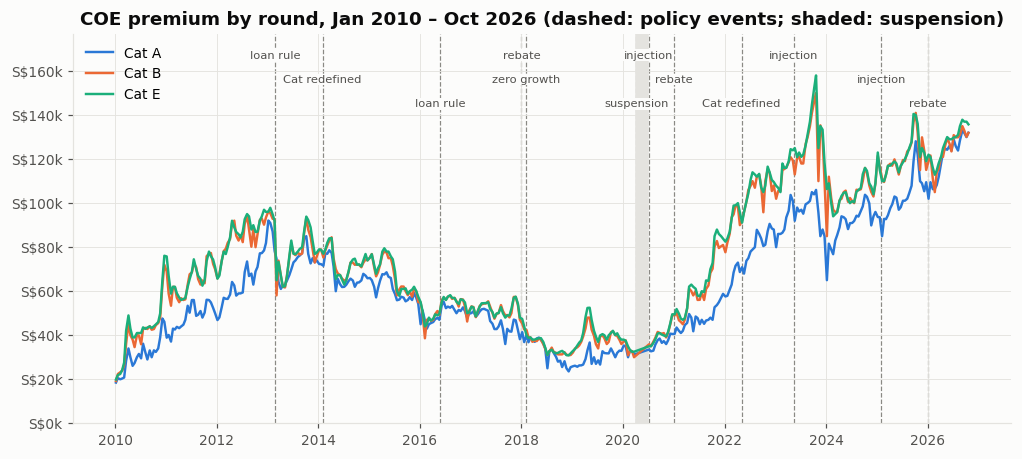

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for c, g in feat.groupby("category"):
    ax.plot(g.date, g.premium, color=CAT_COLORS[c], lw=1.6, label=f"Cat {c}")
short = {"financing_rule": "loan rule", "category_redefinition": "Cat redefined", "quota_change": "zero growth",
         "suspension": "suspension", "injection": "injection", "rebate_change": "rebate"}
ev = events[(events.date <= feat.date.max()) & ~((events.type == "suspension") & (events.date.dt.month == 7))]
ev = ev.drop_duplicates("date")
ymax = feat.premium.max()
for i, e in enumerate(ev.itertuples()):
    ax.axvline(e.date, color="#8a8984", lw=0.8, ls="--", zorder=0)
    ax.text(e.date, ymax * (1.05 - 0.07 * (i % 3)), short[e.type], rotation=0, fontsize=7.5,
            color=INK_2, ha="center", bbox=dict(fc="#fcfcfb", ec="none", pad=0.5))
ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"), color="#e4e3df", zorder=0)
ax.yaxis.set_major_formatter(FuncFormatter(sgd)); ax.set_ylim(0, ymax * 1.12)
ax.set_title("COE premium by round, Jan 2010 – Oct 2026 (dashed: policy events; shaded: suspension)")
ax.legend(loc="upper left")
save(fig, "03_1_premium_events.png"); plt.show()
first = feat[feat.month == "2010-01"].groupby("category").premium.first()
last = feat[(feat.month == CUTOFF_MONTH) & (feat.bidding_no == CUTOFF_ROUND)].set_index("category").premium
low = feat[feat.year.between(2010, 2026)].groupby("category").premium.min()
findings.append(f"Premiums rose from S${first['B']:,.0f} (Cat B, Jan 2010) to S${last['B']:,.0f} (Oct 2026), "
                f"{last['B']/first['B']:.1f}x; Cat A from S${first['A']:,.0f} to S${last['A']:,.0f} "
                f"({last['A']/first['A']:.1f}x). This is why we model the % rise, not the S$ rise.")

## Chart 2 — distribution of the 2-round % rise, by period

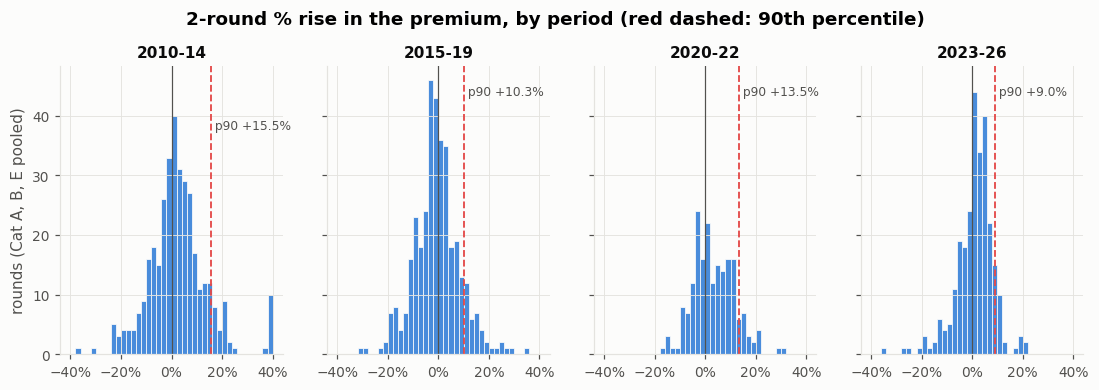

,period,n,mean,median,p90,p95,share_rise,share_gt_10pct,skew,std
0,2010-14,360,0.029,0.018,0.155,0.211,0.594,0.194,1.788,0.135
1,2015-19,360,-0.007,-0.010,0.103,0.148,0.439,0.106,0.248,0.090
2,2020-22,192,0.032,0.022,0.135,0.168,0.620,0.208,0.358,0.083
3,2023-26,270,0.010,0.017,0.090,0.104,0.637,0.067,-0.943,0.074


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True, sharex=True)
bins = np.linspace(-0.4, 0.4, 41)
rows = []
for ax, (p, g) in zip(axes, feat.dropna(subset=["r_2"]).groupby("eda_period", observed=True)):
    ax.hist(g.r_2.clip(-0.4, 0.4), bins=bins, color="#2a78d6", alpha=0.85, edgecolor="#fcfcfb", lw=0.6)
    p90 = g.r_2.quantile(0.9)
    ax.axvline(0, color=INK_2, lw=0.8); ax.axvline(p90, color="#e34948", lw=1.2, ls="--")
    ax.text(p90, ax.get_ylim()[1] * 0.9, f" p90 {p90:+.1%}", color=INK_2, fontsize=8)
    ax.set_title(p, fontsize=10); ax.xaxis.set_major_formatter(PercentFormatter(1, 0))
    rows.append({"period": p, "n": len(g), "mean": g.r_2.mean(), "median": g.r_2.median(),
                 "p90": p90, "p95": g.r_2.quantile(0.95), "share_rise": (g.r_2 > 0).mean(),
                 "share_gt_10pct": (g.r_2 > 0.10).mean(), "skew": g.r_2.skew(), "std": g.r_2.std()})
axes[0].set_ylabel("rounds (Cat A, B, E pooled)")
fig.suptitle("2-round % rise in the premium, by period (red dashed: 90th percentile)", fontweight="bold", y=1.03)
save(fig, "03_2_rise_distribution.png"); plt.show()
dist = pd.DataFrame(rows); dist

In [5]:
d0, d3 = dist.iloc[0], dist.iloc[-1]
sgd_p90 = feat.dropna(subset=["R_2"]).groupby("eda_period", observed=True).R_2.quantile(0.9)
trend = "narrower" if d3.p90 < d0.p90 else "wider"
skews = ", ".join(f"{r.period} {r.skew:+.2f}" for r in dist.itertuples())
findings.append(f"In % terms the 2-round rise is {trend} today than in 2010-14 (90th percentile {d0.p90:+.1%} -> {d3.p90:+.1%}, "
                f"std. dev. {d0['std']:.1%} -> {d3['std']:.1%}), but because premiums are far higher its 90th percentile in S$ "
                f"moved from S${sgd_p90.iloc[0]:,.0f} to S${sgd_p90.iloc[-1]:,.0f}: the dollar risk has not fallen even though % swings have. "
                f"Skewness by period: {skews}.")
b23 = feat[(feat.category == "B") & (feat.year >= 2023)].dropna(subset=["r_2"])
findings.append(f"The 2-round rise in Cat B exceeded 10% in {(b23.r_2 > 0.10).mean():.0%} of rounds since 2023 "
                f"({(b23.r_2 > 0.10).sum()} of {len(b23)}).")

## Chart 3 — rolling 12-round volatility of 1-round changes

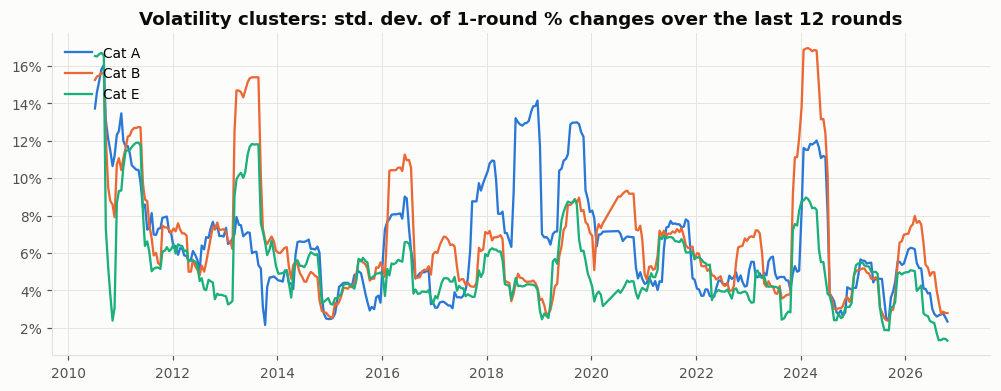

lag-1 autocorrelation of |1-round change|: {'A': np.float64(0.31), 'B': np.float64(0.33), 'E': np.float64(0.32)}
          0.100  0.900
category              
A         0.034  0.115
B         0.036  0.114
E         0.031  0.086


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for c, g in feat.groupby("category"):
    ax.plot(g.date, g.vol_12, color=CAT_COLORS[c], lw=1.5, label=f"Cat {c}")
ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
ax.set_title("Volatility clusters: std. dev. of 1-round % changes over the last 12 rounds")
ax.legend(loc="upper left"); save(fig, "03_3_volatility.png"); plt.show()
acf_abs = {c: acf(g.ret_1.dropna().abs(), nlags=1)[1] for c, g in feat.groupby("category")}
vq = feat.groupby("category").vol_12.quantile([0.1, 0.9]).unstack()
print("lag-1 autocorrelation of |1-round change|:", {k: round(v, 2) for k, v in acf_abs.items()})
print(vq)
findings.append(f"Volatility clusters: the 12-round volatility of Cat B ranged from {vq.loc['B', 0.1]:.1%} (10th pct) "
                f"to {vq.loc['B', 0.9]:.1%} (90th pct), and the lag-1 autocorrelation of absolute 1-round changes is "
                f"{acf_abs['B']:.2f} for Cat B, so calm and turbulent spells persist. Buffers should widen with recent volatility.")

## Chart 4 — bid ratio at t vs the 2-round rise that follows

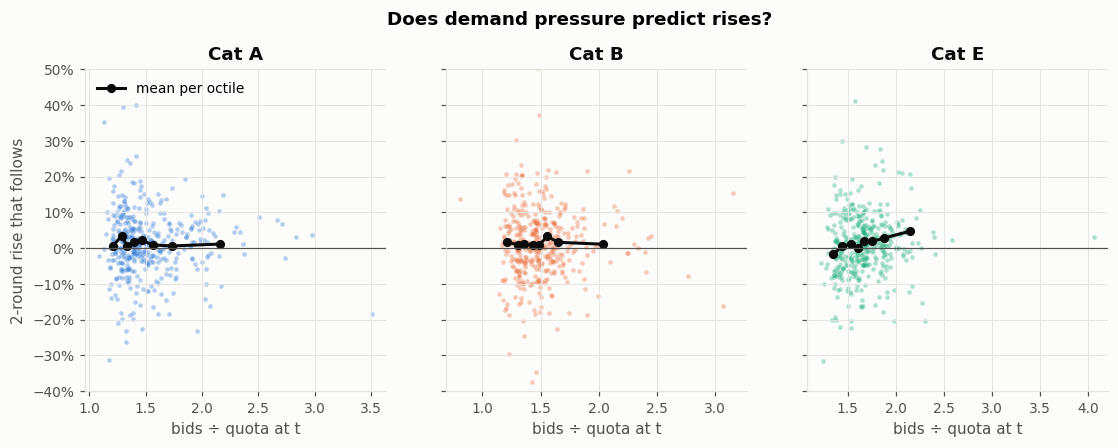

{'A': (np.float64(0.007), np.float64(0.011), np.float64(-0.031)), 'B': (np.float64(0.017), np.float64(0.011), np.float64(-0.003)), 'E': (np.float64(-0.017), np.float64(0.047), np.float64(0.142))}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
binned = {}
for ax, (c, g) in zip(axes, feat.dropna(subset=["r_2"]).groupby("category")):
    ax.scatter(g.bid_ratio, g.r_2, s=9, color=CAT_COLORS[c], alpha=0.35, lw=0)
    g = g.assign(bin=pd.qcut(g.bid_ratio, 8))
    bm = g.groupby("bin", observed=True).agg(x=("bid_ratio", "mean"), y=("r_2", "mean"))
    ax.plot(bm.x, bm.y, color="#0b0b0b", lw=2, marker="o", ms=5, label="mean per octile")
    ax.axhline(0, color=INK_2, lw=0.8); ax.set_title(f"Cat {c}"); ax.set_xlabel("bids ÷ quota at t")
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_ylim(-0.4, 0.5)
    binned[c] = (bm.y.iloc[0], bm.y.iloc[-1], g.bid_ratio.corr(g.r_2))
axes[0].set_ylabel("2-round rise that follows"); axes[0].legend(loc="upper left")
fig.suptitle("Does demand pressure predict rises?", fontweight="bold", y=1.02)
save(fig, "03_4_bidratio_vs_rise.png"); plt.show()
print({c: tuple(round(x, 3) for x in v) for c, v in binned.items()})
lo, hi, r = binned["B"]
findings.append(f"Demand pressure is only a weak signal on its own: in Cat B the mean 2-round rise is {lo:+.1%} in the "
                f"lowest octile of the bid ratio and {hi:+.1%} in the highest (correlation {r:.2f}).")

## Chart 5 — quota and premium over time (two panels, one shared time axis; no dual axis)

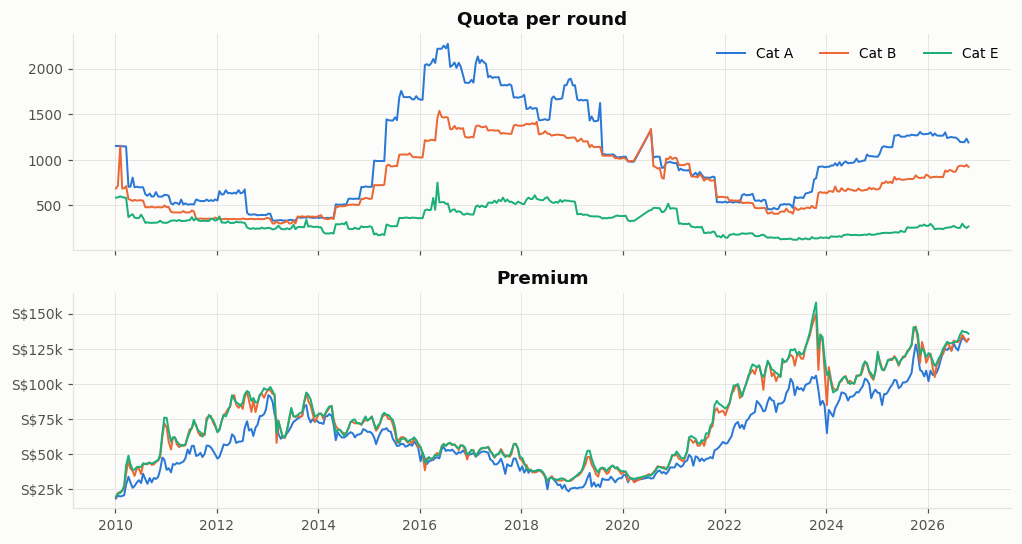

corr(log quota, log premium): {'A': np.float64(-0.28), 'B': np.float64(-0.48), 'E': np.float64(-0.81)}
corr(quarterly quota change, next 2-round rise): {'A': np.float64(-0.07), 'B': np.float64(0.0), 'E': np.float64(-0.06)}


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
for c, g in feat.groupby("category"):
    axes[0].plot(g.date, g.quota, color=CAT_COLORS[c], lw=1.3, label=f"Cat {c}")
    axes[1].plot(g.date, g.premium, color=CAT_COLORS[c], lw=1.3, label=f"Cat {c}")
axes[0].set_title("Quota per round"); axes[1].set_title("Premium")
axes[1].yaxis.set_major_formatter(FuncFormatter(sgd)); axes[0].legend(loc="upper right", ncol=3)
save(fig, "03_5_quota_premium.png"); plt.show()
corr = {c: np.corrcoef(np.log(g.quota), np.log(g.premium))[0, 1] for c, g in feat.groupby("category")}
qq = feat.dropna(subset=["quota_chg_6", "r_2"])
cq = {c: g.quota_chg_6.corr(g.r_2) for c, g in qq.groupby("category")}
print("corr(log quota, log premium):", {k: round(v, 2) for k, v in corr.items()})
print("corr(quarterly quota change, next 2-round rise):", {k: round(v, 2) for k, v in cq.items()})
findings.append(f"Supply moves price in levels: log quota and log premium correlate at {corr['A']:.2f} (A), {corr['B']:.2f} (B), "
                f"{corr['E']:.2f} (E). The 2013 low-quota years coincide with S$70k-90k premiums; the 2017-20 high-quota years with S$30k-50k.")

## Chart 6 — autocorrelation of 1-round changes

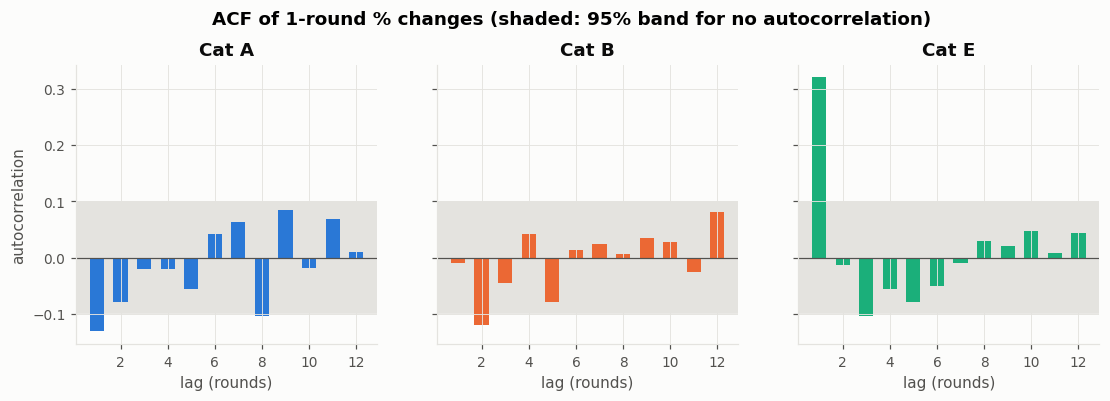

{'A': np.float64(-0.131), 'B': np.float64(-0.009), 'E': np.float64(0.32)}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
ac1 = {}
for ax, (c, g) in zip(axes, feat.groupby("category")):
    x = g.ret_1.dropna()
    a = acf(x, nlags=12); ci = 1.96 / np.sqrt(len(x))
    ax.bar(range(1, 13), a[1:], color=CAT_COLORS[c], width=0.6)
    ax.axhspan(-ci, ci, color="#e4e3df", zorder=0); ax.axhline(0, color=INK_2, lw=0.8)
    ax.set_title(f"Cat {c}"); ax.set_xlabel("lag (rounds)"); ac1[c] = a[1]
axes[0].set_ylabel("autocorrelation")
fig.suptitle("ACF of 1-round % changes (shaded: 95% band for no autocorrelation)", fontweight="bold", y=1.03)
save(fig, "03_6_acf.png"); plt.show()
print({k: round(v, 3) for k, v in ac1.items()})
findings.append(f"Little linear momentum: the lag-1 autocorrelation of 1-round changes is {ac1['A']:+.2f} (A), "
                f"{ac1['B']:+.2f} (B), {ac1['E']:+.2f} (E). Momentum features should add little to point forecasts; "
                f"the value is in the spread (volatility), not the direction.")

## ADF stationarity test (decides whether Phase 5 models levels or changes)

In [10]:
rows = []
for c, g in feat.groupby("category"):
    lp = g.log_premium.dropna(); d = lp.diff().dropna()
    for name, s in [("log premium", lp), ("1-round change of log premium", d)]:
        stat, p, *_ = adfuller(s, autolag="AIC")
        rows.append({"category": c, "series": name, "ADF stat": stat, "p-value": p})
adf = pd.DataFrame(rows); print(adf.to_string(index=False))
pl = adf[adf.series == "log premium"]["p-value"]; pd_ = adf[adf.series != "log premium"]["p-value"]
findings.append(f"The log premium is non-stationary (ADF p = {pl.min():.2f}-{pl.max():.2f}) while its changes are stationary "
                f"(p < {max(pd_.max(), 0.001):.3f}), so Phase 5 models changes (rises), not levels.")

category                        series  ADF stat  p-value
       A                   log premium    -0.992    0.756
       A 1-round change of log premium    -8.171    0.000
       B                   log premium    -1.441    0.562
       B 1-round change of log premium   -10.937    0.000
       E                   log premium    -2.478    0.121
       E 1-round change of log premium   -11.299    0.000


## Summary statistics of the 2-round rise (S$), and the no-buffer dealer

In [11]:
def stats(g):
    R = g.R_2.dropna()
    return pd.Series({"n": len(R), "mean": R.mean(), "median": R.median(), "p90": R.quantile(0.9),
                      "p95": R.quantile(0.95), "max": R.max(), "share_underwater_no_buffer": (R > 0).mean(),
                      "avg_loss_if_underwater": R[R > 0].mean()})
summ_all = feat.groupby("category").apply(stats)
summ_23 = feat[feat.year >= 2023].groupby("category").apply(stats)
print("All rounds 2010-2026"); display(summ_all.round(0))
print("Since 2023"); display(summ_23.round(0))
summ_23.assign(period="2023-26").to_csv(PROC / "eda_rise_summary.csv")

All rounds 2010-2026


,n,mean,median,p90,p95,max,share_underwater_no_buffer,avg_loss_if_underwater
category,,,,,,,,
A,394.000,560.000,827.000,"6,726.000","8,533.000","20,216.000",1.000,"3,930.000"
B,394.000,539.000,798.000,"8,731.000","11,694.000","24,111.000",1.000,"5,329.000"
E,394.000,574.000,656.000,"8,357.000","11,468.000","26,212.000",1.000,"4,843.000"


Since 2023


,n,mean,median,p90,p95,max,share_underwater_no_buffer,avg_loss_if_underwater
category,,,,,,,,
A,90.000,"1,067.000","2,077.000","8,503.000","10,021.000","20,216.000",1.000,"4,920.000"
B,90.000,606.000,"2,716.000","10,036.000","12,220.000","20,099.000",1.000,"6,180.000"
E,90.000,643.000,"1,629.000","9,269.000","12,799.000","18,999.000",1.000,"5,537.000"


In [12]:
s = summ_23
findings.insert(0, f"A no-buffer dealer quoting the latest premium and buying 2 rounds later was underwater on "
                f"{s.loc['A','share_underwater_no_buffer']:.0%} of Cat A and {s.loc['B','share_underwater_no_buffer']:.0%} of Cat B "
                f"sales since 2023, losing S${s.loc['A','avg_loss_if_underwater']:,.0f} (A) and S${s.loc['B','avg_loss_if_underwater']:,.0f} (B) "
                f"per underwater car on average; the worst 2-round rise was S${s['max'].max():,.0f}.")
findings.append(f"For Cat B since 2023, the 90th percentile of the 2-round rise is S${s.loc['B','p90']:,.0f} and the 95th "
                f"S${s.loc['B','p95']:,.0f} (plan's preliminary check: S$9,977 and S$11,889).")
text = "# EDA findings (generated by 03_eda.ipynb)\n\n" + "\n".join(f"{i}. {f}" for i, f in enumerate(findings, 1))
(REPORT / "eda_findings.md").write_text(text)
print(text)

# EDA findings (generated by 03_eda.ipynb)

1. A no-buffer dealer quoting the latest premium and buying 2 rounds later was underwater on 64% of Cat A and 64% of Cat B sales since 2023, losing S$4,920 (A) and S$6,180 (B) per underwater car on average; the worst 2-round rise was S$20,216.
2. Premiums rose from S$19,190 (Cat B, Jan 2010) to S$131,901 (Oct 2026), 6.9x; Cat A from S$18,502 to S$132,004 (7.1x). This is why we model the % rise, not the S$ rise.
3. In % terms the 2-round rise is narrower today than in 2010-14 (90th percentile +15.5% -> +9.0%, std. dev. 13.5% -> 7.4%), but because premiums are far higher its 90th percentile in S$ moved from S$8,631 to S$9,161: the dollar risk has not fallen even though % swings have. Skewness by period: 2010-14 +1.79, 2015-19 +0.25, 2020-22 +0.36, 2023-26 -0.94.
4. The 2-round rise in Cat B exceeded 10% in 8% of rounds since 2023 (7 of 90).
5. Volatility clusters: the 12-round volatility of Cat B ranged from 3.6% (10th pct) to 11.4% (90th pct),